In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif,
    RFE
)

from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

In [3]:
columns_to_remove = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

df_clean = df.drop(columns=columns_to_remove)

X = df_clean.drop(columns=["Machine failure"])
y = df_clean["Machine failure"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [5]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [7]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [8]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


In [9]:
X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

X_train_df.head()

,num__Air temperature [K],num__Process temperature [K],num__Rotational speed [rpm],num__Torque [Nm],num__Tool wear [min],cat__Type_H,cat__Type_L,cat__Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0.0,0.0,1.0
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0.0,0.0,1.0
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0


In [10]:
correlation_df = pd.concat(
    [
        X_train_df,
        y_train.rename("Machine failure")
    ],
    axis=1
)

correlations = correlation_df.corr()["Machine failure"].drop(
    "Machine failure"
)

print(correlations.sort_values(ascending=False))

num__Torque [Nm]                0.190034
num__Tool wear [min]            0.099214
num__Air temperature [K]        0.086001
cat__Type_L                     0.047160
num__Process temperature [K]    0.040849
cat__Type_H                    -0.024860
cat__Type_M                    -0.034239
num__Rotational speed [rpm]    -0.039966
Name: Machine failure, dtype: float64


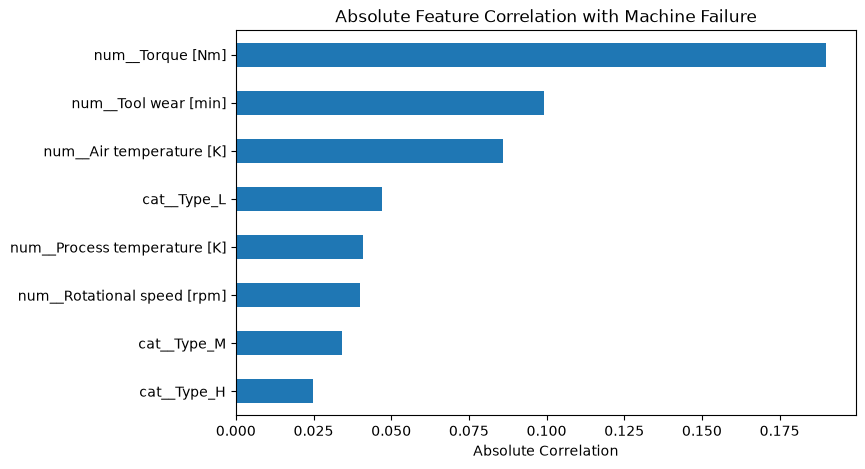

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

correlations.abs().sort_values(ascending=True).plot(
    kind="barh"
)

plt.title("Absolute Feature Correlation with Machine Failure")
plt.xlabel("Absolute Correlation")

plt.show()

In [12]:
SelectKBest(
    score_func=mutual_info_classif,
    k=...
)

,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function mut...001FD1E8CD9B0>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",Ellipsis


In [13]:
selector = SelectKBest(
    score_func=mutual_info_classif,
    k="all"
)

X_train_selected = selector.fit_transform(
    X_train_df,
    y_train
)

In [14]:
scores = selector.scores_

feature_scores = pd.DataFrame({
    "Feature": feature_names,
    "Score": scores
})

feature_scores = feature_scores.sort_values(
    by="Score",
    ascending=False
)

feature_scores

,Feature,Score
3,num__Torque [Nm],0.044332
2,num__Rotational speed [rpm],0.034242
4,num__Tool wear [min],0.011325
0,num__Air temperature [K],0.007258
6,cat__Type_L,0.003426
1,num__Process temperature [K],0.003223
7,cat__Type_M,0.001581
5,cat__Type_H,0.000000


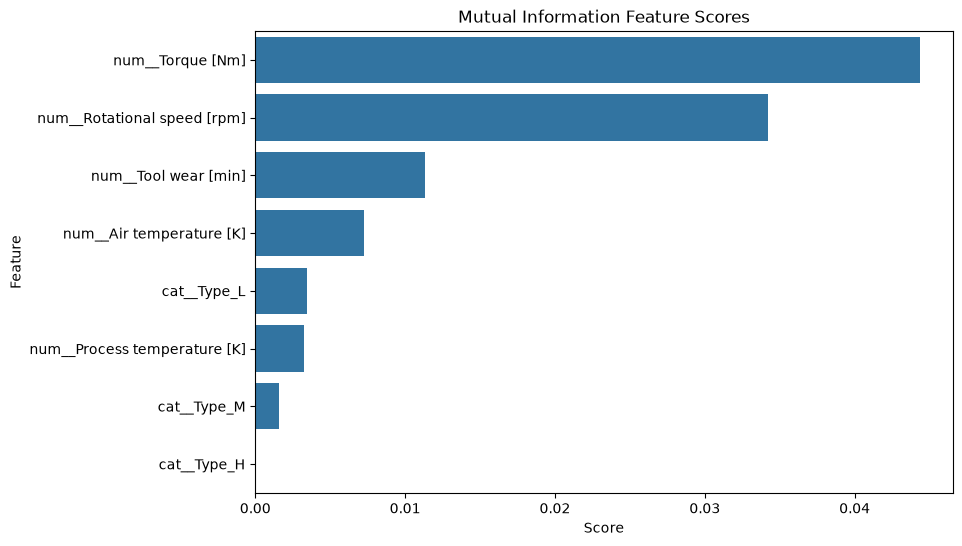

In [15]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_scores,
    x="Score",
    y="Feature"
)

plt.title("Mutual Information Feature Scores")

plt.show()

In [16]:
k = 5

selector_kbest = SelectKBest(
    score_func=mutual_info_classif,
    k=k
)

X_train_kbest = selector_kbest.fit_transform(
    X_train_df,
    y_train
)

X_test_kbest = selector_kbest.transform(
    X_test_df
)

In [17]:
selected_features_kbest = feature_names[
    selector_kbest.get_support()
]

print("Selected features:")
for feature in selected_features_kbest:
    print(feature)

Selected features:
num__Air temperature [K]
num__Process temperature [K]
num__Rotational speed [rpm]
num__Torque [Nm]
num__Tool wear [min]


In [18]:
k_values = [2, 3, 4, 5, 6, 7, 8]

for k in k_values:

    selector = SelectKBest(
        score_func=mutual_info_classif,
        k=k
    )

    selector.fit(X_train_df, y_train)

    selected = feature_names[selector.get_support()]

    print(f"\nK = {k}")
    print(selected)


K = 2
['num__Rotational speed [rpm]' 'num__Torque [Nm]']

K = 3
['num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]']

K = 4
['num__Air temperature [K]' 'num__Rotational speed [rpm]'
 'num__Torque [Nm]' 'num__Tool wear [min]']

K = 5
['num__Process temperature [K]' 'num__Rotational speed [rpm]'
 'num__Torque [Nm]' 'num__Tool wear [min]' 'cat__Type_M']

K = 6
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_L']

K = 7
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_L' 'cat__Type_M']

K = 8
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']


In [19]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

In [20]:
rfe = RFE(
    estimator=model,
    n_features_to_select=5
)

rfe.fit(X_train_df, y_train)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).",LogisticRegre...max_iter=1000)
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",5
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,LogisticRegression,LogisticRegre...max_iter=1000)
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['num__Air temperature [K]','num__Process temperature [K]', 'num__Rotational speed [rpm]',...,'cat__Type_H','cat__Type_L', 'cat__Type_M']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(5)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,8


In [21]:
rfe_features = feature_names[rfe.support_]

print("RFE Selected Features:")

for feature in rfe_features:
    print(feature)

RFE Selected Features:
num__Air temperature [K]
num__Process temperature [K]
num__Rotational speed [rpm]
num__Torque [Nm]
num__Tool wear [min]


In [22]:
rfe_results = pd.DataFrame({
    "Feature": feature_names,
    "Ranking": rfe.ranking_
})

rfe_results.sort_values("Ranking")

,Feature,Ranking
0,num__Air temperature [K],1
1,num__Process temperature [K],1
2,num__Rotational speed [rpm],1
3,num__Torque [Nm],1
4,num__Tool wear [min],1
7,cat__Type_M,2
5,cat__Type_H,3
6,cat__Type_L,4


In [23]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif

selector = SelectKBest(
    score_func=mutual_info_classif,
    k="all"
)

selector.fit(X_train_df, y_train)

feature_scores = pd.DataFrame({
    "Feature": feature_names,
    "Score": selector.scores_
})

feature_scores = feature_scores.sort_values(
    by="Score",
    ascending=False
)

feature_scores

,Feature,Score
3,num__Torque [Nm],0.045148
2,num__Rotational speed [rpm],0.035113
4,num__Tool wear [min],0.013133
0,num__Air temperature [K],0.007277
1,num__Process temperature [K],0.002814
7,cat__Type_M,0.000777
6,cat__Type_L,0.000572
5,cat__Type_H,0.000000


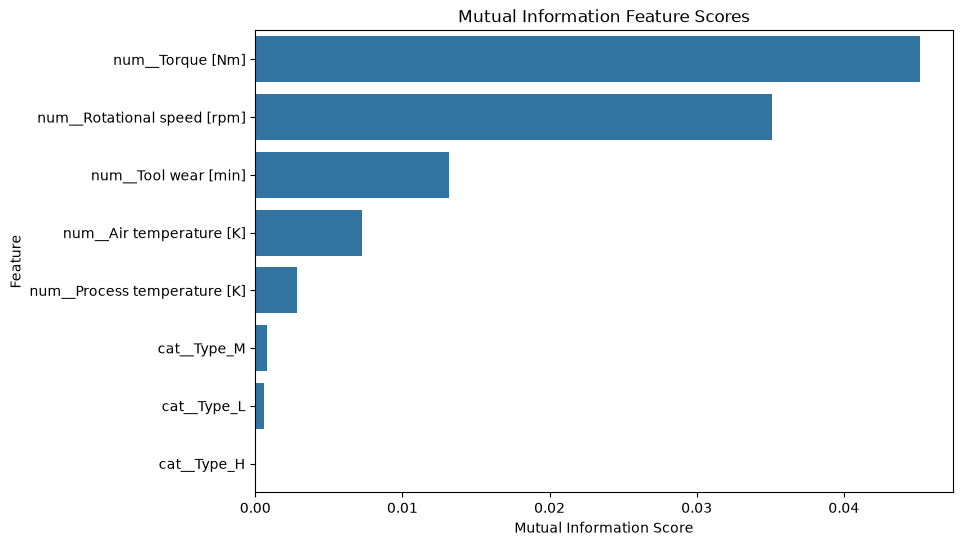

In [24]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=feature_scores,
    x="Score",
    y="Feature"
)

plt.title("Mutual Information Feature Scores")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.show()